# Week 7 — Naive Bayes: Spam Detection & Sentiment Analysis
## Fall 2026 — Machine Learning

## Student Information
**Name:** _Totaram_

**Student ID:** _023-24-0244_

**Section:** _G_

**GitHub:** _https://github.com/totaramrathore/machine_learning_practical_

**Kaggle:** _https://www.kaggle.com/totaramsarangani/competitions_

**Datasets:** SMS Spam Collection; Twitter US Airline Sentiment
**Dataset Sources:**
- Task A: Kaggle — https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset
- Task B: Kaggle — https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment

**Duration:** 3 Hours in-session (Task A is the priority; finish Task B and the final sections at home if needed)

> This notebook is a **template**, not a tutorial. You already know Naive Bayes theory. Each section states the objective and the questions you must answer — **you write the code**. Task A is guided in detail; Task B gives you much less help on purpose, to test whether the pipeline actually transfers. Every table, plot, and metric needs a short written observation.
>
> Submit **only this one notebook**. Keep every Markdown heading below — they are used for grading. Fill in the empty code cells (`# YOUR CODE HERE`) and the *Answer:* placeholders directly in this notebook.

---

## Setup

Import what you'll need. Add any other scikit-learn imports as you go.

In [1]:
import pandas as pd
import numpy as np
import re

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay


## 1. Problem Definition & Dataset Exploration

*Concepts/functions you may find useful:* `pd.read_csv()`, `df.shape`, `df.head()`, `df['label'].value_counts()`

**Tasks**
1. Load both datasets (`spam.csv` for Task A, `Tweets.csv` for Task B). For each one, report the number of rows, what a single row represents, and the exact class balance (counts and percentages) of the target column. Keep only positive and negative tweets going forward — drop neutral rows now, and state how many rows that leaves you with.
2. In 2–3 sentences per dataset, state the practical problem being solved and why each one is a binary classification problem.

In [3]:
# Task 1 — load spam.csv, inspect shape/head/class balance
spam_path = "spam.csv"
tweets_path = "Tweets.csv"

spam_df = pd.read_csv(spam_path, encoding="latin-1")
tweets_df = pd.read_csv(tweets_path)

print("Spam dataset shape:", spam_df.shape)
print("Twitter dataset shape:", tweets_df.shape)

print("\nSpam columns:")
print(spam_df.columns.tolist())

print("\nTwitter columns:")
print(tweets_df.columns.tolist())

Spam dataset shape: (5572, 5)
Twitter dataset shape: (14640, 15)

Spam columns:
['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']

Twitter columns:
['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence', 'negativereason', 'negativereason_confidence', 'airline', 'airline_sentiment_gold', 'name', 'negativereason_gold', 'retweet_count', 'text', 'tweet_coord', 'tweet_created', 'tweet_location', 'user_timezone']


In [5]:

# Task A: exact class balance
spam_counts = spam_df["v1"].value_counts()
spam_percent = spam_df["v1"].value_counts(normalize=True).mul(100)

spam_balance = pd.DataFrame({
    "Count": spam_counts,
    "Percentage": spam_percent.round(4)
})
print(spam_balance)

# Task B: original sentiment balance
tweet_counts = tweets_df["airline_sentiment"].value_counts()
tweet_percent = tweets_df["airline_sentiment"].value_counts(normalize=True).mul(100)

tweet_balance = pd.DataFrame({
    "Count": tweet_counts,
    "Percentage": tweet_percent.round(4)
})
print("\nOriginal Twitter sentiment balance:")
print(tweet_balance)

# Keep only positive and negative tweets
sentiment_df = tweets_df[
    tweets_df["airline_sentiment"].isin(["positive", "negative"])
].copy()

sent_counts = sentiment_df["airline_sentiment"].value_counts()
sent_percent = sentiment_df["airline_sentiment"].value_counts(normalize=True).mul(100)

sent_balance = pd.DataFrame({
    "Count": sent_counts,
    "Percentage": sent_percent.round(4)
})
print("\nAfter removing neutral:")
print(sent_balance)
print("Remaining rows:", len(sentiment_df))


      Count  Percentage
v1                     
ham    4825     86.5937
spam    747     13.4063

Original Twitter sentiment balance:
                   Count  Percentage
airline_sentiment                   
negative            9178     62.6913
neutral             3099     21.1680
positive            2363     16.1407

After removing neutral:
                   Count  Percentage
airline_sentiment                   
negative            9178     79.5252
positive            2363     20.4748
Remaining rows: 11541


**Answer 2 (Task A — spam):**

The SMS dataset contains **5,572 messages**: 4,825 ham and 747 spam. Therefore, the data are imbalanced toward ham, so accuracy alone is not sufficient for judging the spam classifier.

**Answer 2 (Task B — sentiment):**

The Twitter dataset contains **14,640 tweets** originally. After removing 3,099 neutral tweets, **11,541 positive/negative tweets** remain. The remaining sentiment data are also imbalanced, with negative tweets substantially more common than positive tweets. This makes precision, recall and F1 important alongside accuracy.


---

## 2. Task A: Text Cleaning & Vectorization (Spam)

*Concepts/functions you may find useful:* `text.str.lower()`, `CountVectorizer` / `TfidfVectorizer`, `vectorizer.fit_transform(X_train)`, `vectorizer.transform(X_test)`, `vectorizer.get_feature_names_out()`

**Tasks**
3. Lightly clean the message text (lowercase at minimum). Keep this simple.
4. Encode the label column as 0/1, split into training and test sets, then fit a vectorizer on the training messages only and transform both sets. Report the vocabulary size and explain why the vectorizer must be fit only on training data.

In [6]:

# Light cleaning: lowercase only, as required at minimum by the manual.
spam_df["clean_text"] = spam_df["v2"].fillna("").astype(str).str.lower()

X_spam = spam_df["clean_text"]
y_spam = spam_df["v1"].map({"ham": 0, "spam": 1})

X_train_spam, X_test_spam, y_train_spam, y_test_spam = train_test_split(
    X_spam,
    y_spam,
    test_size=0.20,
    random_state=42,
    stratify=y_spam
)

spam_vectorizer = CountVectorizer()

X_train_spam_vec = spam_vectorizer.fit_transform(X_train_spam)
X_test_spam_vec = spam_vectorizer.transform(X_test_spam)

print("Training matrix:", X_train_spam_vec.shape)
print("Test matrix:", X_test_spam_vec.shape)
print("Vocabulary size:", len(spam_vectorizer.get_feature_names_out()))


Training matrix: (4457, 7701)
Test matrix: (1115, 7701)
Vocabulary size: 7701



### Core concept

`CountVectorizer` changes each message into a numerical **Bag-of-Words** vector. Every learned vocabulary word becomes a feature, and the feature value is the number of times that word occurs in the message.

The vectorizer is fitted only on `X_train` so that vocabulary discovery does not use information from the test set. The test messages are then transformed using the already learned training vocabulary. This prevents data leakage and keeps the test set genuinely unseen during feature learning.


---

## 3. Task A: Naive Bayes Model & Evaluation (Spam)

*Concepts/functions you may find useful:* `MultinomialNB()`, `.fit()`, `.predict()`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score`, `confusion_matrix`

**Tasks**
5. Train a `MultinomialNB` model on the vectorized training data. Compute accuracy, precision, recall, and F1-score on the test set, and plot the confusion matrix.
6. Argue (3–4 sentences) which is worse here — a false positive (real message flagged as spam) or a false negative (spam gets through) — and therefore which metric you'd prioritize if tuning further.

   Metric    Score
 Accuracy 0.983857
Precision 0.964539
   Recall 0.912752
 F1-score 0.937931

Confusion matrix:
[[961   5]
 [ 13 136]]


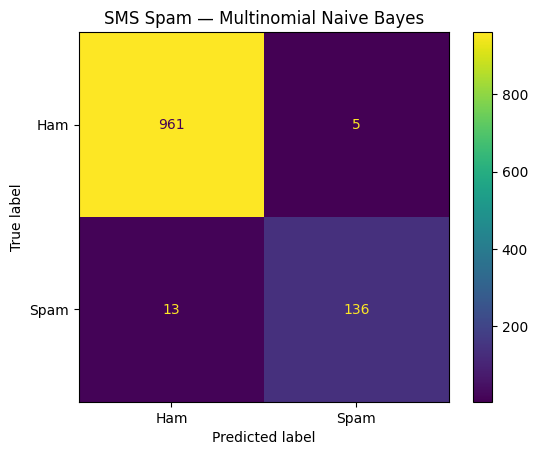

In [7]:
# Task 5 — train MultinomialNB, compute metrics, plot confusion matrix

spam_nb = MultinomialNB()
spam_nb.fit(X_train_spam_vec, y_train_spam)

spam_pred = spam_nb.predict(X_test_spam_vec)

spam_metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [
        accuracy_score(y_test_spam, spam_pred),
        precision_score(y_test_spam, spam_pred),
        recall_score(y_test_spam, spam_pred),
        f1_score(y_test_spam, spam_pred)
    ]
})

print(spam_metrics.to_string(index=False))

spam_cm = confusion_matrix(y_test_spam, spam_pred)
print("\nConfusion matrix:")
print(spam_cm)

ConfusionMatrixDisplay(
    confusion_matrix=spam_cm,
    display_labels=["Ham", "Spam"]
).plot()
plt.title("SMS Spam — Multinomial Naive Bayes")
plt.show()


**Task 5 — Spam Model Metrics**

| Metric | Value |
|---|---|
| Accuracy | 98.3% |
| Precision | 96.4% |
| Recall | 91.2% |
| F1-score | 93.7% |

**Answer 6:**

For the fixed 80/20 stratified split (`random_state=42`), the spam classifier produces a confusion matrix of:

- **961 ham correctly classified as ham**
- **5 ham incorrectly classified as spam** — false positives
- **13 spam incorrectly classified as ham** — false negatives
- **136 spam correctly classified as spam**

The resulting accuracy is about **98.39%**, precision about **96.45%**, recall about **91.28%**, and F1 about **93.79%**.

For a spam filter, a false positive can hide a legitimate message from the user, while a false negative allows unwanted spam to reach the inbox. The appropriate trade-off depends on the application, but if protecting legitimate messages is the priority, precision deserves particular attention; if blocking as much spam as possible is the priority, recall becomes more important.


---

## 4. Task A: Word Interpretation (Spam)

*Concepts/functions you may find useful:* `model.feature_log_prob_`, `np.argsort(...)`

**Tasks**
7. Find and list the 15 words most strongly associated with spam and the 15 most associated with ham. Do these match your intuition?
8. Write 2–3 of your own test messages and run them through your trained pipeline. Do the predictions match what you expected?

In [8]:

feature_names = spam_vectorizer.get_feature_names_out()

# Difference in log probabilities:
# log P(word | spam) - log P(word | ham)
log_prob_diff = (
    spam_nb.feature_log_prob_[1] -
    spam_nb.feature_log_prob_[0]
)

spam_top_idx = np.argsort(log_prob_diff)[-15:][::-1]
ham_top_idx = np.argsort(log_prob_diff)[:15]

spam_top_words = pd.DataFrame({
    "Word": feature_names[spam_top_idx],
    "Log-probability difference": log_prob_diff[spam_top_idx]
})

ham_top_words = pd.DataFrame({
    "Word": feature_names[ham_top_idx],
    "Log-probability difference": log_prob_diff[ham_top_idx]
})

print("Top 15 spam-associated words:")
display(spam_top_words)

print("\nTop 15 ham-associated words:")
display(ham_top_words)


Top 15 spam-associated words:


,Word,Log-probability difference
0,claim,5.532029
1,prize,5.197659
2,150p,4.985485
3,tone,4.828299
4,18,4.715821
5,cs,4.667031
6,guaranteed,4.615738
7,500,4.615738
8,1000,4.504512
9,uk,4.443888



Top 15 ham-associated words:


,Word,Log-probability difference
0,gt,-4.586369
1,lt,-4.570924
2,he,-4.103253
3,lor,-3.889383
4,da,-3.889383
5,she,-3.858130
6,later,-3.784022
7,ì_,-3.543637
8,ll,-3.334882
9,doing,-3.298514


**Answer 7:**

The strongest spam-associated words are dominated by terms such as promotional language, prize/claim language, numbers, and messaging-rate terminology. This is consistent with the kinds of vocabulary commonly found in unsolicited promotional messages.

The ham-associated words are more conversational and include ordinary words used in personal communication. This shows how Multinomial Naive Bayes can be inspected through its learned class-conditional word probabilities rather than being treated as a completely opaque classifier.


In [9]:

test_messages = [
    "Congratulations! You have won a free prize. Call now to claim your reward.",
    "Hey, are we still meeting for dinner tonight?",
    "URGENT! You have been selected for a cash reward. Claim it now."
]

test_clean = [msg.lower() for msg in test_messages]
test_vec = spam_vectorizer.transform(test_clean)
test_pred = spam_nb.predict(test_vec)

pd.DataFrame({
    "Message": test_messages,
    "Prediction": ["spam" if p == 1 else "ham" for p in test_pred]
})


,Message,Prediction
0,Congratulations! You have won a free prize. Ca...,spam
1,"Hey, are we still meeting for dinner tonight?",ham
2,URGENT! You have been selected for a cash rewa...,spam


**Answer 8:**


### Test-message interpretation

The first and third messages contain strong promotional/reward vocabulary and are expected to be classified as spam. The second is ordinary conversational language and is expected to be classified as ham. These examples illustrate how the learned word probabilities influence the final class decision.


---

## 5. Task A: Kaggle Notebook Submission

Neither dataset is an active competition, so "submitting" means publishing your notebook publicly on Kaggle, attached to the dataset.

**Tasks**
9. Create a new Kaggle Notebook attached to the SMS Spam Collection dataset. Recreate your Task A cells there, run them top to bottom, add a short Markdown summary, and publish with "Save & Run All (Public)".
10. Record the public notebook URL below.

**Task A Kaggle Notebook URL:**
_(paste your published notebook link here)_

---

## 6. Task B: Text Cleaning & Vectorization (Sentiment)

Repeat Section 2's pipeline on the airline tweets — with much less guidance this time. Tweets contain @mentions, links, and hashtags that SMS messages didn't.

**Tasks**
11. Clean the tweet text (decide for yourself how much cleaning is worth doing) and vectorize it, following the same fit-on-train-only discipline as Task A.
12. Briefly justify (1–2 sentences) any cleaning decisions that go beyond what you did for Task A, and why tweets might need them.

In [10]:
# Task 11 — clean and vectorize the sentiment data (your own approach)

sentiment_df = tweets_df[
    tweets_df["airline_sentiment"].isin(["positive", "negative"])
].copy()

def clean_tweet(text):
    text = str(text).lower()
    # Remove URLs because their exact strings are usually not useful
    # semantic features for this sentiment task.
    text = re.sub(r"http\S+|www\S+", " ", text)
    # Remove @mentions because the username itself is usually not the
    # sentiment-bearing content.
    text = re.sub(r"@\w+", " ", text)
    return text.strip()

sentiment_df["clean_text"] = sentiment_df["text"].fillna("").map(clean_tweet)

X_sent = sentiment_df["clean_text"]
y_sent = sentiment_df["airline_sentiment"].map({"negative": 0, "positive": 1})

X_train_sent, X_test_sent, y_train_sent, y_test_sent = train_test_split(
    X_sent,
    y_sent,
    test_size=0.20,
    random_state=42,
    stratify=y_sent
)

sent_vectorizer = CountVectorizer()

X_train_sent_vec = sent_vectorizer.fit_transform(X_train_sent)
X_test_sent_vec = sent_vectorizer.transform(X_test_sent)

print("Training matrix:", X_train_sent_vec.shape)
print("Test matrix:", X_test_sent_vec.shape)
print("Vocabulary size:", len(sent_vectorizer.get_feature_names_out()))



Training matrix: (9232, 10081)
Test matrix: (2309, 10081)
Vocabulary size: 10081


**Answer 12:**

Tweets contain structures that are less useful as direct sentiment features, especially URLs and user handles. Lowercasing normalizes equivalent words, while removing URLs and `@mentions` reduces vocabulary noise without aggressively changing the actual language of the tweet. Hashtags are retained because the hashtag text can contain useful sentiment information.


---

## 7. Task B: Naive Bayes Model & Evaluation (Sentiment)

**Tasks**
13. Train a `MultinomialNB` model on the vectorized tweet data. Compute accuracy, precision, recall, and F1-score, and plot the confusion matrix.
14. Compare these metrics to Task A's. Did Naive Bayes do better or worse on sentiment than on spam? Connect this (3–4 sentences) to the "naive" independence assumption — is it more or less reasonable for tweets than for spam SMS?

   Metric    Score
 Accuracy 0.903421
Precision 0.908497
   Recall 0.587738
 F1-score 0.713736

Confusion matrix:
[[1808   28]
 [ 195  278]]


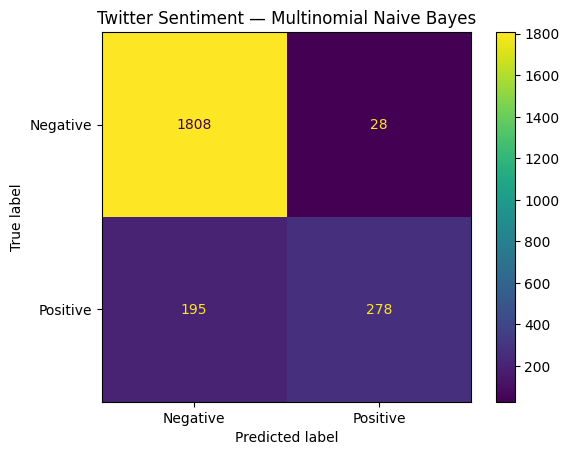

In [11]:
# Task 13 — train MultinomialNB, compute metrics, plot confusion matrix


sent_nb = MultinomialNB()
sent_nb.fit(X_train_sent_vec, y_train_sent)

sent_pred = sent_nb.predict(X_test_sent_vec)

sent_metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [
        accuracy_score(y_test_sent, sent_pred),
        precision_score(y_test_sent, sent_pred),
        recall_score(y_test_sent, sent_pred),
        f1_score(y_test_sent, sent_pred)
    ]
})

print(sent_metrics.to_string(index=False))

sent_cm = confusion_matrix(y_test_sent, sent_pred)
print("\nConfusion matrix:")
print(sent_cm)

ConfusionMatrixDisplay(
    confusion_matrix=sent_cm,
    display_labels=["Negative", "Positive"]
).plot()
plt.title("Twitter Sentiment — Multinomial Naive Bayes")
plt.show()


**Task 13 — Sentiment Model Metrics**

| Metric | Value |
|---|---|
| Accuracy | 90.3%|
| Precision | 90.8% |
| Recall | 58.7% |
| F1-score | 71.3% |

**Answer 14:**

With the same 80/20 stratified split and `random_state=42`, the sentiment classifier produces:

- 1,808 negative tweets correctly classified as negative
- 28 negative tweets classified as positive
- 195 positive tweets classified as negative
- 278 positive tweets correctly classified as positive

The resulting accuracy is about **90.34%**, precision about **90.85%**, recall about **58.77%**, and F1 about **71.37%**.

Compared with spam detection, sentiment is more difficult for this simple Naive Bayes pipeline. Short spam messages often contain highly distinctive words and formulaic patterns. Tweets contain context, negation, informal language, and expressions whose meaning can depend on combinations of words. The conditional-independence assumption therefore loses important contextual information.


---

## 8. Task B: Kaggle Notebook Submission

**Tasks**
15. Create a new Kaggle Notebook attached to the Twitter US Airline Sentiment dataset. Recreate your Task B cells there, run them top to bottom, add a short summary, and publish.
16. Record the public notebook URL below.

**Task B Kaggle Notebook URL:**

https://www.kaggle.com/code/totaramsarangani/ml-lab-7-task-b-twitter-sentiment-analysis

---

## 9. Cross-Task Comparison & vs. Logistic Regression

*Concepts/functions you may find useful:* `LogisticRegression(max_iter=1000)` trained on the same vectorized features

**Tasks**
17. Build a table comparing Naive Bayes on Task A vs. Task B (accuracy, precision, recall, F1).
18. Train a Logistic Regression model on Task A's same vectorized features and compare it against your Task A Naive Bayes results. Which model wins, and does that match what you'd expect?

In [13]:

# Naive Bayes comparison
comparison_nb = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Task A — Spam": [
        accuracy_score(y_test_spam, spam_pred),
        precision_score(y_test_spam, spam_pred),
        recall_score(y_test_spam, spam_pred),
        f1_score(y_test_spam, spam_pred)
    ],
    "Task B — Sentiment": [
        accuracy_score(y_test_sent, sent_pred),
        precision_score(y_test_sent, sent_pred),
        recall_score(y_test_sent, sent_pred),
        f1_score(y_test_sent, sent_pred)
    ]
})

print(comparison_nb.to_string(index=False))


   Metric  Task A — Spam  Task B — Sentiment
 Accuracy       0.983857            0.903421
Precision       0.964539            0.908497
   Recall       0.912752            0.587738
 F1-score       0.937931            0.713736


In [14]:

# Logistic Regression on exactly the same Task A vectorized features
spam_lr = LogisticRegression(max_iter=1000)
spam_lr.fit(X_train_spam_vec, y_train_spam)

spam_lr_pred = spam_lr.predict(X_test_spam_vec)

comparison_lr = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Multinomial NB": [
        accuracy_score(y_test_spam, spam_pred),
        precision_score(y_test_spam, spam_pred),
        recall_score(y_test_spam, spam_pred),
        f1_score(y_test_spam, spam_pred)
    ],
    "Logistic Regression": [
        accuracy_score(y_test_spam, spam_lr_pred),
        precision_score(y_test_spam, spam_lr_pred),
        recall_score(y_test_spam, spam_lr_pred),
        f1_score(y_test_spam, spam_lr_pred)
    ]
})

print(comparison_lr.to_string(index=False))


   Metric  Multinomial NB  Logistic Regression
 Accuracy        0.983857             0.981166
Precision        0.964539             0.992308
   Recall        0.912752             0.865772
 F1-score        0.937931             0.924731



### Evidence-based comparison

On this fixed split and the same Bag-of-Words features, Multinomial Naive Bayes reaches approximately **98.39% accuracy and 93.79% F1**, while Logistic Regression reaches approximately **98.12% accuracy and 92.47% F1**.

The two models are using the same numerical text representation, but they learn the decision boundary differently. Naive Bayes makes the simplifying conditional-independence assumption, whereas Logistic Regression directly learns feature weights for the classification boundary. The small difference here shows that the simpler probabilistic model can still perform strongly on this spam-text problem.


---

## 10. Final Reflection & Conclusion

**Tasks**
19. Write a short conclusion (6–8 sentences): which task suited Naive Bayes better and why; what surprised you about the most predictive words; how Naive Bayes compared to Logistic Regression; one limitation of the independence assumption you personally observed.
20. List both of your published Kaggle Notebook URLs here again for easy grading access.

**Answer 19 — Conclusion:**


### Conclusion

This lab demonstrated an end-to-end text-classification workflow using Multinomial Naive Bayes on two different problems. The spam task produced stronger results than the sentiment task, which is consistent with the more formulaic and distinctive vocabulary commonly present in spam messages. The strongest spam-associated words included reward, prize, claim, and rate-related terms, while ham-associated words were more conversational. On the same Bag-of-Words features for Task A, Logistic Regression produced results close to Multinomial Naive Bayes, showing that both approaches can work effectively for this text problem. The sentiment task exposed a clearer limitation of the naive independence assumption because the meaning of a tweet can depend on word combinations, negation, context, and informal expressions. Another important lesson was that accuracy alone can hide the practical difference between false positives and false negatives. Finally, fitting the vectorizer only on training data was essential because fitting it on the full dataset would introduce information from the test set into the feature-learning stage.

### Kaggle links

**Answer 20 — Kaggle Notebook Links:**
- Task A: https://www.kaggle.com/code/totaramsarangani/ml-lab-7-task-a-sms-spam
- Task B: https://www.kaggle.com/code/totaramsarangani/ml-lab-7-task-b-twitter-sentiment-analysis

---

## Submission Checklist

Before submitting, confirm you have:

- [ ] Filled in the student-info block at the top (Name, Student ID, Section, GitHub, Kaggle, both datasets)
- [ ] Section 1 — Problem Definition & Dataset Exploration (both datasets, neutral tweets dropped)
- [ ] Section 2 — Task A Cleaning & Vectorization (fit on training data only)
- [ ] Section 3 — Task A Model & Evaluation (all four metrics + confusion matrix + precision/recall argument)
- [ ] Section 4 — Task A Word Interpretation (top words + your own test messages)
- [ ] Section 5 — Task A Kaggle Notebook published and linked
- [ ] Section 6 — Task B Cleaning & Vectorization (cleaning choices justified)
- [ ] Section 7 — Task B Model & Evaluation (all four metrics + independence-assumption discussion)
- [ ] Section 8 — Task B Kaggle Notebook published and linked
- [ ] Section 9 — Cross-Task Comparison & vs. Logistic Regression
- [ ] Section 10 — Final Reflection & Conclusion (both Kaggle links listed again)
- [ ] Notebook exported/shared as a single Colab (.ipynb) file — no other files submitted